# Estado del arte: fugas suaves frente a las velocidades de corrida de 2023 y el análisis de sensibilidad de 2019 del BCE

**Pregunta:** ¿Es la fuga suave de la prueba de tensión de liquidez de 2019 del BCE, que sigue el producto, lo bastante rápida para las corridas de 2023, y cómo se comparan los períodos de supervivencia del producto con los que el BCE informó para 103 bancos?

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los notebooks 01 a 06 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este notebook puedes:

- ubicar la tensión de liquidez del producto en el estado del arte que encontró la investigación: la prueba de tensión de liquidez de 2019 del BCE, los principios de Basilea, el informe sobre la turbulencia de 2023 y la teoría de las corridas bancarias;
- comparar la fuga suave de LiST con la corrida rápida sobre el mismo balance, en períodos de supervivencia y en la proporción de depósitos perdida al horizonte de cada corrida de 2023;
- correr la tercera severidad de LiST, Base, que el producto no usa, y comparar la salida a 30 días del LCR y los períodos de supervivencia con la velocidad de las corridas de 2023 y con las medianas del BCE;
- decir qué muestra y qué no muestra esta comparación sobre el producto.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Cuatro documentos versionados del caso C16 (agregados reales del reporte de llamada de la FDIC del banco que quebró el 2023-03-10 hasta el 2022-12-31, comportamiento y depósitos sintéticos, clase de licencia `mirror-allowed`): las tres variantes de trayectoria `list-adverse.json`, `list-extreme.json` y `fast-run.json`, y `lcr-standard.json`, todos en `data/derived/C16/`. Las corridas observadas son la Tabla A.1 del informe del BCBS sobre la turbulencia de 2023, guardada por el motor como `TABLE_A1` dentro de los términos de extracto limitado del BIS.

La corrida rápida se calibra solo con las filas anteriores a 2023 y se evalúa con las filas de 2023 (notebook 04); cada proporción modelada de abajo es la salida acumulada de los segmentos del documento sobre la base de depósitos del modelo. Los montos están en miles de USD.

In [2]:
# Cargar los cuatro documentos versionados (el notebook está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
documents = {}
for name in ("list-adverse", "list-extreme", "fast-run", "lcr-standard"):
    path = ROOT / "data" / "derived" / "C16" / f"{name}.json"
    documents[name] = json.loads(path.read_text(encoding="utf-8"))
    baked = documents[name]["provenance"]["riskvalidation_version"]
    print(name, "| calculado con riskvalidation", baked, "| instalado", rv.__version__)

variants = {name: documents[name] for name in ("list-adverse", "list-extreme", "fast-run")}

list-adverse | calculado con riskvalidation 1.0.1 | instalado 1.0.1
list-extreme | calculado con riskvalidation 1.0.1 | instalado 1.0.1
fast-run | calculado con riskvalidation 1.0.1 | instalado 1.0.1
lcr-standard | calculado con riskvalidation 1.0.1 | instalado 1.0.1


## Método

### Paso 1: el período de supervivencia de las tres variantes

La comparación necesita una medida que todas las variantes compartan: el período de supervivencia, el primer día en que la posición neta de liquidez se vuelve negativa, con "sobrevive el horizonte" cuando nunca lo hace (notebook 01). Las tres variantes difieren en la velocidad de la fuga: LiST Adverso y Extremo usan las tasas diarias suaves de las tablas del BCE, y la corrida rápida pone en el segmento corporativo no asegurado la tasa calibrada con las corridas anteriores a 2023, en un horizonte agudo de 5 días. La celda siguiente calcula el período de supervivencia y la NLP mínima de cada variante a partir de su serie NLP versionada con el motor.

In [3]:
# El período de supervivencia y la NLP mínima de cada variante, desde su serie NLP versionada, con el motor
from riskvalidation.liquidity.ladder import minimum_nlp, survival_period

print(f"{'variante':14s}{'horizonte':>10s}{'supervivencia':>24s}{'NLP mínima (mil mill. USD)':>29s}{'día':>6s}")
for name, document in variants.items():
    nlp = np.array(document["outputs"]["path"]["ladder"]["nlp"])
    result = survival_period(nlp)
    low, low_day = minimum_nlp(nlp)
    survival_text = "sobrevive el horizonte" if result.survives else f"día {result.day}"
    print(f"{name:14s}{result.horizon:10d}{survival_text:>24s}{low / 1e6:29.2f}{low_day:6d}")

variante       horizonte           supervivencia   NLP mínima (mil mill. USD)   día
list-adverse         125                  día 62                       -40.97   125
list-extreme         125                  día 41                       -65.65   125
fast-run               5  sobrevive el horizonte                        13.80     1


### Paso 2: la proporción de depósitos perdida al horizonte de cada corrida

El período de supervivencia depende del CBC y de las salidas a la vez. Para comparar la velocidad de la fuga con lo ocurrido usamos solo la salida: para una corrida que perdió una proporción $F_i$ de sus depósitos en $n_i$ días (fila $i$ de la Tabla A.1) la contraparte del modelo es la salida acumulada de los segmentos en esos mismos $n_i$ días, como proporción de la base de depósitos $B$:

$$\hat F_i = \frac{1}{B} \sum_{s} \sum_{d \le n_i} O_s(d), \qquad \text{error}_i = F_i - \hat F_i$$

Una fila cuyo horizonte excede la escalera de una variante no puede evaluarse en ella (la corrida rápida tiene 5 días). La celda siguiente calcula cada proporción modelada a partir del saldo inicial y las tasas diarias de los segmentos versionados con el motor, e imprime las filas del horizonte más corto al más largo. Un error positivo significa que el modelo pierde menos de lo que perdió la corrida.

In [4]:
# La proporción modelada al horizonte de cada corrida de la Tabla A.1, para cada variante, desde las salidas del motor
from riskvalidation.liquidity.ladder import behavioural_outflows
from riskvalidation.liquidity.runoff import TABLE_A1

modelled = {}
for name, document in variants.items():
    segments = document["outputs"]["path"]["ladder"]["segments"]
    opening = np.array([s["opening_balance"] for s in segments])
    horizon = len(segments[0]["outflows"])
    rates = np.array([s["daily_rates"] or np.ones(horizon) for s in segments])
    base = document["outputs"]["scoring"]["model_deposit_base"]
    outflow = np.cumsum(behavioural_outflows(opening, rates).sum(axis=0))
    shares = {}
    for run in TABLE_A1:
        shares[run.row_id] = None if run.days > len(outflow) else outflow[run.days - 1] / base
    modelled[name] = shares

print(f"{'banco':16s}{'año':>6s}{'días':>6s}{'observada':>11s}{'Adverso':>10s}{'Extremo':>10s}{'rápida':>10s}")
for run in sorted(TABLE_A1, key=lambda r: (r.days, r.year)):
    cells = ["-" if modelled[n][run.row_id] is None else f"{modelled[n][run.row_id]:.4f}" for n in modelled]
    left = f"{run.bank:16s}{run.year:6d}{run.days:6d}{run.outflow_share:11.2f}"
    print(left + f"{cells[0]:>10s}{cells[1]:>10s}{cells[2]:>10s}")

banco              año  días  observada   Adverso   Extremo    rápida
SVB UK            2023     1       0.30    0.0854    0.0887    0.1263
Signature         2023     1       0.20    0.0854    0.0887    0.1263
SVB               2023     2       0.85    0.0915    0.0980    0.1708
Northern Rock     2007     4       0.20    0.1036    0.1164    0.2528
WaMu              2008    10       0.10    0.1390    0.1694         -
IndyMac           2008    14       0.08    0.1618    0.2029         -
Icesave           2008    75       0.20    0.4425    0.5722         -
First Republic    2023    90       0.57    0.4955    0.6323         -
Credit Suisse     2023    90       0.21    0.4955    0.6323         -


La celda siguiente dibuja la proporción modelada frente a la proporción observada de cada corrida que una variante puede evaluar, en ejes logarítmicos: un punto sobre la diagonal es un modelo que pierde lo que perdió la corrida, un punto bajo ella un modelo que pierde menos.

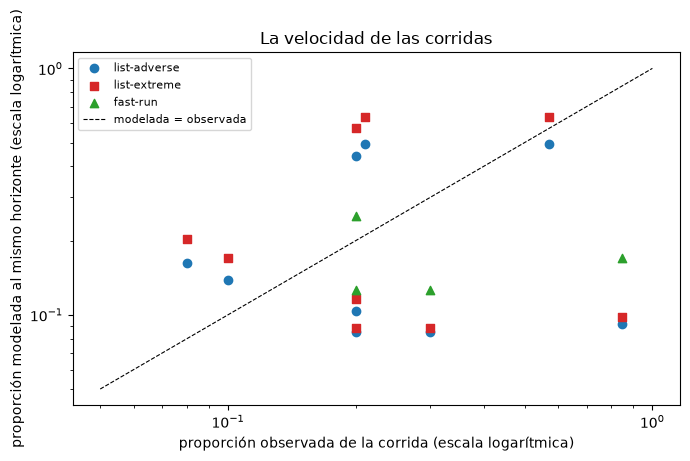

In [5]:
# Dibujar la proporción modelada frente a la observada de cada corrida, para las tres variantes
fig, ax = plt.subplots(figsize=(7, 4.5))
for (name, shares), color, marker in zip(modelled.items(), ("tab:blue", "tab:red", "tab:green"), ("o", "s", "^")):
    points = [(run.outflow_share, shares[run.row_id]) for run in TABLE_A1 if shares[run.row_id] is not None]
    ax.scatter([p[0] for p in points], [p[1] for p in points], color=color, marker=marker, label=name)
ax.plot([0.05, 1.0], [0.05, 1.0], color="black", linestyle="--", linewidth=0.8, label="modelada = observada")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("proporción observada de la corrida (escala logarítmica)")
ax.set_ylabel("proporción modelada al mismo horizonte (escala logarítmica)")
ax.set_title("La velocidad de las corridas")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Los puntos de las corridas rápidas, las de uno y dos días a la derecha del gráfico, quedan bajo la diagonal, lo que significa que el modelo pierde menos de lo que perdió la corrida. Las tres variantes pierden 0,0854, 0,0887 y 0,1263 de la base de depósitos en las corridas de un día (SVB UK, 0,30, y Signature, 0,20) y 0,0915, 0,0980 y 0,1708 en los dos días de SVB (0,85). La corrida rápida, calibrada antes de 2023, es la que más se acerca y aun así llega a cerca de una quinta parte de la pérdida de SVB. Las corridas lentas de 2008 y Credit Suisse quedan sobre la diagonal para las variantes suaves, es decir, esas variantes las cubren, mientras Northern Rock (0,20 en 4 días, 0,2528 para la corrida rápida) solo la cubre la corrida rápida y First Republic (0,57 en 90 días) solo la variante Extrema. La figura compara proporciones al horizonte de cada corrida y no dice nada del CBC que se les opone.

## Estado del arte

Lo que encontró la investigación, con la fuente de cada punto. Solo se citan las fuentes que lista el SDD.

- **La prueba de tensión de liquidez de 2019 del BCE (LiST).** Define la posición neta de liquidez, el período de supervivencia y el efecto acantilado, y hace salir los depósitos de vencimiento abierto con tasas diarias constantes capitalizadas en días relevantes; en sus resultados 103 bancos informaron una mediana del período de supervivencia de 176 días bajo el choque Adverso y de 122 días bajo el Extremo, y los choques son solo idiosincráticos (BCE, 2019, nota metodológica y anexo de resultados).
- **Los principios de Basilea.** El Principio 10 pide a los bancos someter a tensión su liquidez en una variedad de escenarios de corto y largo plazo, específicos de la institución y de todo el mercado, individualmente y en combinación (BCBS, 2008).
- **La turbulencia de 2023.** El informe del BCBS documenta la velocidad de las corridas de 2023 frente a las anteriores en la Tabla A.1 (SVB 85% en 2 días; First Republic 57% en 90 días) y plantea como preguntas abiertas métricas como una capacidad de contrapeso a cinco días, el período de supervivencia y una métrica de liquidez sin supuestos de fuga (BCBS, 2023). La revisión de la Reserva Federal encontró salidas de más de 40 mil millones de USD el 9 de marzo, con la administración esperando 100 mil millones más el día siguiente, y que la prueba de tensión interna de liquidez del banco se apoyaba en referencias de pares que no eran comparables (Federal Reserve, 2023).
- **Teoría y corrida digital.** Diamond y Dybvig (1983) muestran que un contrato de depósito a la vista tiene un equilibrio bueno y un equilibrio de corrida, y que el seguro de depósitos elimina el segundo; la proporción no asegurada es entonces un motor del riesgo de corrida, no un modelo calibrado. Cookson et al. (2026) relacionan la exposición a las redes sociales con las pérdidas bursátiles de los bancos en la corrida sobre Silicon Valley Bank; el producto no lo modela.
- **Pérdidas no realizadas.** Valorar a mercado los activos de los bancos de EE. UU. tras el alza de tasas de 2022 da grandes pérdidas no realizadas, y estas reducen el CBC efectivo y pueden gatillar corridas (Jiang et al., 2024; notebook 03).
- **La escalera de modelos.** El dosier de investigación ordena los modelos de una tensión de liquidez desde una escalera contractual estática a una escalera conductual, un motor de escenarios, la calibración de velocidades de corrida con sensibilidades, y la tensión de liquidez inversa; no encontró un motor de código abierto maduro para toda la escalera (UNVERIFIED más allá de la búsqueda del dosier). El producto implementa los cinco peldaños; el precio de transferencia de fondos no está implementado.

Los tres pasos siguientes corren el motor sobre los datos del caso frente a estos puntos: la tercera severidad de LiST, que el producto no usa; la velocidad de SVB frente a las tablas y al LCR; y los períodos de supervivencia del caso frente a las medianas que el BCE informó para 103 bancos.

### Paso 3: la severidad Base de LiST

La prueba de 2019 tiene tres severidades, y el producto corre dos de ellas como variantes. El motor guarda la tercera, Base, con las mismas clases (BCE, 2019, Tabla 3.3). La celda siguiente la compone sobre los segmentos y la escalera del documento LiST Adverso y calcula su período de supervivencia y su NLP mínima.

In [6]:
# La severidad Base de LiST sobre los segmentos y la escalera del documento LiST Adverso
from riskvalidation.liquidity.ladder import net_liquidity_position
from riskvalidation.liquidity.scenarios import compose_scenario, list_scenario

document = variants["list-adverse"]["outputs"]
lad = document["path"]["ladder"]
row = next(r for r in document["conventions"]["variant_scenarios"]["rows"] if r["variant"] == "list-adverse")
segments = {s["segment"]: (s["list_class"], s["opening_balance"]) for s in lad["segments"]}
args = (row["scenario_family"], row["phase"], list_scenario("baseline"))
scenario = compose_scenario(*args, segments, row["horizon_days"])
contractual = np.sum([c["amounts"] for c in lad["other_outflows"]], axis=0)
inflows = np.sum([c["amounts"] for c in lad["inflows"]], axis=0)
total_outflows = scenario.outflows().sum(axis=0) + contractual
baseline_nlp = net_liquidity_position(np.array(lad["cbc_total"]), total_outflows, inflows)
baseline = survival_period(baseline_nlp)
low, low_day = minimum_nlp(baseline_nlp)

print("sobrevive el horizonte:", "sí" if baseline.survives else "no", "| horizonte (días):", baseline.horizon)
print("NLP mínima (miles de millones de USD) y su día:", round(low / 1e6, 2), low_day)

sobrevive el horizonte: sí | horizonte (días): 125
NLP mínima (miles de millones de USD) y su día: 22.06 1


Bajo Base el banco sobrevive todo el horizonte, y su NLP nunca cae bajo 22,06 mil millones de USD (el día 1, cuando el segmento financiero sale completo): las clases de vencimiento abierto de los segmentos tienen tasa cero, así que las únicas salidas son ese segmento y las contractuales. La severidad no es una tensión para este balance, y por eso el producto conserva Adverso y Extremo; es un piso de la familia de tablas, sin corrida alguna.

### Paso 4: cuánto más rápido fue 2023 que las tablas

Poner las corridas y las tablas en la misma escala toma la tasa diaria implícita $q = 1-(1-F)^{1/n}$ (notebook 02). La tasa de Silicon Valley Bank (85% en 2 días; Federal Reserve, 2023) frente a la tasa que LiST Adverso y Extremo dan a la clase corporativa no asegurada, y frente a la mayor salida de depósitos a 30 días del LCR (40% en 30 días, el tope del rango de la Tabla A.1), muestra la distancia. La celda siguiente calcula las tasas y las razones.

In [7]:
# La tasa diaria implícita de SVB frente a las tasas de LiST de la clase corporativa y al tope del rango LCR
from riskvalidation.liquidity.runoff import LIST_PARAMETERS, TABLE_A1_LCR_RANGE, daily_rate_from_cumulative

svb = next(run for run in TABLE_A1 if run.row_id == "svb-2023")
corporate = "non-operational-non-financial-corporates"
rates = {severity: LIST_PARAMETERS[severity]["open_maturity"][corporate] for severity in ("adverse", "extreme")}
low_share, high_share, lcr_days = TABLE_A1_LCR_RANGE
rates["lcr top"] = daily_rate_from_cumulative(high_share, lcr_days)
rates["svb"] = daily_rate_from_cumulative(svb.outflow_share, svb.days)

print("tasa diaria implícita de SVB (85 por ciento en 2 días):", round(rates["svb"], 6))
for name, label in (("adverse", "Adverso"), ("extreme", "Extremo"), ("lcr top", "tope LCR")):
    print(f"{label:9s} | tasa diaria: {rates[name]:.8f} | SVB sobre ella: {rates['svb'] / rates[name]:.1f}")
lcr = documents["lcr-standard"]["outputs"]["lcr"]
print("LCR del documento:", round(lcr["ratio"], 4))
print("salida neta del LCR sobre su stock de HQLA:", round(lcr["net_outflows"] / lcr["hqla"]["hqla"], 4))

tasa diaria implícita de SVB (85 por ciento en 2 días): 0.612702
Adverso   | tasa diaria: 0.00688541 | SVB sobre ella: 89.0
Extremo   | tasa diaria: 0.01065229 | SVB sobre ella: 57.5
tope LCR  | tasa diaria: 0.01688337 | SVB sobre ella: 36.3
LCR del documento: 0.4726
salida neta del LCR sobre su stock de HQLA: 2.1158


La celda siguiente dibuja las cuatro tasas diarias en un eje logarítmico: las dos tasas de LiST para la clase corporativa no asegurada, el tope del rango del LCR y la tasa de SVB.

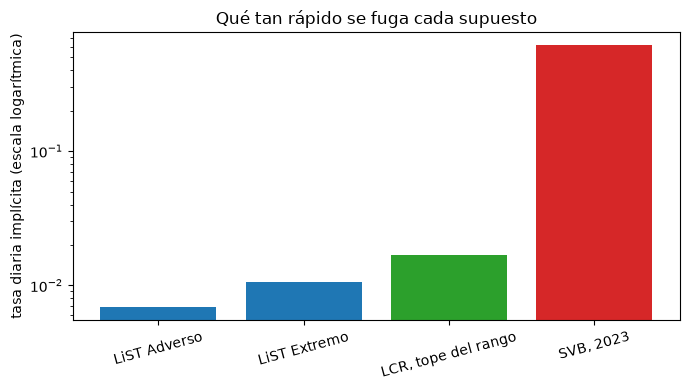

In [8]:
# Dibujar las tasas diarias de las tablas LiST, del rango LCR y de SVB en un eje logarítmico
labels = ["LiST Adverso", "LiST Extremo", "LCR, tope del rango", "SVB, 2023"]
values = [rates["adverse"], rates["extreme"], rates["lcr top"], rates["svb"]]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(labels, values, color=["tab:blue", "tab:blue", "tab:green", "tab:red"])
ax.set_yscale("log")
ax.set_ylabel("tasa diaria implícita (escala logarítmica)")
ax.set_title("Qué tan rápido se fuga cada supuesto")
ax.tick_params(axis="x", labelrotation=15)
fig.tight_layout()
plt.show()

Cada barra queda aproximadamente un orden de magnitud sobre la anterior. Las tasas de LiST para la clase corporativa no asegurada, 0,00688541 y 0,01065229 al día, están abajo; el tope del rango del LCR, 0,016883, es el siguiente escalón; y la tasa de SVB, 0,612702, es 89,0 veces la tasa Adversa, 57,5 veces la Extrema y 36,3 veces la del LCR. La salida neta del LCR es 2,1158 veces el stock de HQLA, así que incluso el más rápido de los supuestos regulatorios deja al banco corto, pero no a la velocidad de 2023. Las barras comparan tasas implícitas de una corrida cada una: SVB es una sola observación.

### Paso 5: los períodos de supervivencia frente a las medianas de la prueba de 2019

La celda siguiente pone los períodos de supervivencia del producto junto a las medianas de la prueba de 2019. Las medianas son cifras propias del BCE, ingresadas aquí como constantes con su fuente, porque no pertenecen a ningún documento versionado. Describen 103 bancos reales, y este caso es un banco de comportamiento sintético, así que la comparación muestra el orden de magnitud del método, no un ranking.

In [9]:
# Los períodos de supervivencia del producto junto a las medianas de la prueba del BCE de 2019 (103 bancos)
LIST_2019_MEDIAN = {"adverse": 176, "extreme": 122}  # mediana informada del período de supervivencia, en días

ours = {}
for severity, name in (("adverse", "list-adverse"), ("extreme", "list-extreme")):
    nlp = np.array(variants[name]["outputs"]["path"]["ladder"]["nlp"])
    ours[severity] = survival_period(nlp).day
    median = LIST_2019_MEDIAN[severity]
    print(f"LiST {severity:8s} | este caso (días): {ours[severity]} | mediana de los 103 bancos (días): {median}")
    print(f"   razón: {ours[severity] / LIST_2019_MEDIAN[severity]:.2f}")

LiST adverse  | este caso (días): 62 | mediana de los 103 bancos (días): 176
   razón: 0.35
LiST extreme  | este caso (días): 41 | mediana de los 103 bancos (días): 122
   razón: 0.34


La celda siguiente dibuja los períodos de supervivencia de este caso frente a las medianas de la prueba de 2019.

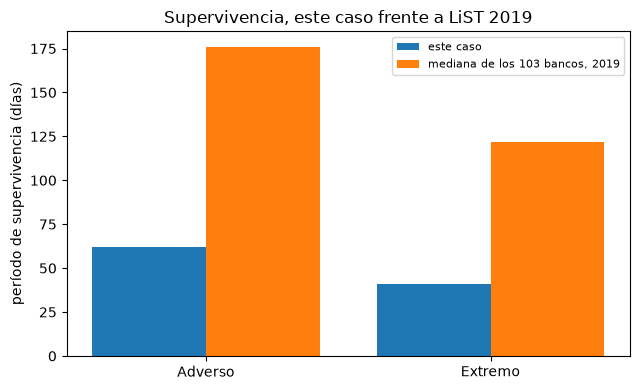

In [10]:
# Dibujar los períodos de supervivencia de este caso frente a las medianas de la prueba de 2019
positions = np.arange(2)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(positions - 0.2, [ours["adverse"], ours["extreme"]], width=0.4, label="este caso")
medians = [LIST_2019_MEDIAN["adverse"], LIST_2019_MEDIAN["extreme"]]
ax.bar(positions + 0.2, medians, width=0.4, label="mediana de los 103 bancos, 2019")
ax.set_xticks(positions)
ax.set_xticklabels(["Adverso", "Extremo"])
ax.set_ylabel("período de supervivencia (días)")
ax.set_title("Supervivencia, este caso frente a LiST 2019")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

En ambas severidades el caso dura cerca de un tercio de lo que informó el banco mediano de la muestra de 2019: 62 días frente a 176 bajo Adverso y 41 frente a 122 bajo Extremo, razones de 0,35 y 0,34. Las dos razones son casi iguales, así que la forma de la respuesta a la severidad es la misma aunque el nivel difiera. La causa es el balance, no el método: el caso tiene una gran base corporativa no asegurada y un CBC que cubre solo una parte, y los 103 bancos son balances reales con sus propios depósitos y activos. La figura dice que el mismo método da períodos de supervivencia del orden de meses; no dice que el banco quede bajo la muestra.

## Resultados

**Respuesta:** No, la fuga suave es demasiado lenta para las corridas de 2023. En las corridas de uno y dos días las tres variantes pierden de 0,0854 a 0,1263 de la base de depósitos donde SVB UK y Signature perdieron 0,30 y 0,20, y de 0,0915 a 0,1708 donde SVB perdió 0,85. La tasa diaria implícita de SVB, 0,612702, es 89,0 veces la tasa que LiST Adverso da a la clase corporativa no asegurada y 36,3 veces el tope del rango de depósitos del LCR. Frente a la prueba de 2019 los períodos de supervivencia de este caso, 62 y 41 días, son 0,35 y 0,34 de las medianas de 103 bancos (176 y 122 días), así que el método da meses de supervivencia y el balance explica el nivel.

- **Supervivencia.** La NLP de LiST Adverso se vuelve negativa el día 62 y la de Extremo el día 41, ambas con su mínimo el día 125 (-40,97 y -65,65 mil millones de USD); la corrida rápida sobrevive su horizonte de 5 días, con un mínimo de 13,80 mil millones el día 1. Bajo la severidad Base, que el producto no usa, el banco sobrevive el horizonte y su NLP mínima es 22,06 mil millones el día 1.
- **Velocidad al horizonte de cada corrida.** En las corridas de uno y dos días las tres variantes pierden mucho menos que las corridas: 0,0854, 0,0887 y 0,1263 frente a 0,30 (SVB UK) y 0,20 (Signature), y 0,0915, 0,0980 y 0,1708 frente a 0,85 (SVB). La corrida rápida, calibrada antes de 2023, se acerca más pero sigue en cerca de una quinta parte de la pérdida de SVB. A los 90 días el panorama cambia: Adverso (0,4955) queda bajo el 0,57 de First Republic y Extremo (0,6323) sobre él, y ambos sobre el 0,21 de Credit Suisse; las corridas lentas de 2008 (Icesave, IndyMac, WaMu) quedan todas cubiertas con holgura, mientras que Northern Rock (0,20 en 4 días frente a 0,1036 y 0,1164) no. Las tasas suaves son conservadoras para corridas lentas y demasiado lentas para las rápidas.
- **Cuánto más rápido.** La tasa diaria implícita de SVB, 0,612702, es 89,0 veces la tasa que LiST Adverso da a la clase corporativa no asegurada y 57,5 veces la de Extremo, y 36,3 veces la tasa diaria del tope del rango de depósitos del LCR (40% en 30 días, 0,016883). La salida neta del LCR del documento (0,4726) es 2,1158 veces su stock de HQLA.
- **Frente al estado del arte.** Los períodos de supervivencia de este caso, 62 y 41 días, son cerca de un tercio de las medianas de la prueba de 2019, 176 y 122 días (razones de 0,35 y 0,34). Los 103 bancos son balances reales con sus propios depósitos y activos, y este caso es un banco con comportamiento sintético, así que la razón dice que el mismo método da períodos de supervivencia del orden de meses, no que el banco quede bajo la muestra.

Lo que esta comparación no muestra: que la corrida rápida del producto sea un pronóstico (es una calibración rotulada con corridas anteriores a 2023), que el banco habría sobrevivido o fallado con estos números (su comportamiento es sintético), ni que LiST esté equivocado (responde la pregunta para la que fue diseñado: una fuga lenta e idiosincrática en seis meses).

## Resumen

- La fuga suave de LiST y la corrida rápida son dos respuestas a dos preguntas; sobre el mismo balance difieren en órdenes de magnitud en la velocidad que suponen.
- Evaluadas frente a las corridas de 2023, las variantes suaves pierden mucho menos que las corridas de uno y dos días (SVB UK, Signature, SVB) y son conservadoras para las corridas lentas de 2008; la corrida rápida, calibrada solo con corridas anteriores, mejora sobre ellas y aun así pierde cerca de una quinta parte de lo que perdió SVB.
- La salida a 30 días del LCR es más rápida que las tasas suaves de LiST pero mucho más lenta que las corridas de 2023, y la tercera severidad de LiST, Base, no es una tensión para este balance.
- El producto sigue el método del BCE y agrega lo que el dosier lista como el resto de la escalera; no afirma un pronóstico.

**Qué probar a continuación.** Cambia la corrida de la comparación del paso 4 por la de First Republic (57% en 90 días) y mira qué tan lejos está su tasa diaria de las tablas LiST; luego sigue con el notebook 08, que convierte la distancia a las corridas de 2023 en un número.

## Referencias

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, results annex (2019-10-07). https://www.bankingsupervision.europa.eu/press/pr/date/2019/html/ssm.pr191007_annex~537c259b6d.en.pdf
- BCBS (2008), Principles for sound liquidity risk management and supervision, Principle 10. https://www.bis.org/publ/bcbs144.htm
- BCBS (2023), Report on the 2023 banking turmoil, Box A, Table A.1. https://www.bis.org/bcbs/publ/d555.htm
- Federal Reserve Board (2023-04-28), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- Diamond, D. W. and Dybvig, P. H. (1983), Bank runs, deposit insurance, and liquidity, Journal of Political Economy 91(3). https://doi.org/10.1086/261155
- Cookson, J. A., Fox, C., Gil-Bazo, J., Imbet, J. F. and Schiller, C. (2026), Social media as a bank run catalyst, Journal of Financial Economics 176. https://doi.org/10.1016/j.jfineco.2025.104218
- Jiang, E. X., Matvos, G., Piskorski, T. and Seru, A. (2024), Monetary tightening and U.S. bank fragility in 2023: mark-to-market losses and uninsured depositor runs?, Journal of Financial Economics 159. https://doi.org/10.1016/j.jfineco.2024.103899